In [1]:
import os
import zipfile
import random
import warnings
from pathlib import Path


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2


In [3]:
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

In [4]:
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.16.1


In [5]:
dataset_path = Path("C:\\Users\\KIIT\\Downloads\\PRCP-1001-RiceLeaf\\Data")

image_extensions = [".jpg", ".jpeg", ".png"]

image_paths = []

for ext in image_extensions:
    image_paths.extend(dataset_path.rglob(f"*{ext}"))

print("Total images:", len(image_paths))

for folder in sorted(set(p.parent for p in image_paths)):
    print(folder.name)

Total images: 119
Bacterial leaf blight
Brown spot
Leaf smut


In [6]:
data = []

for img_path in image_paths:

    disease = img_path.parent.name

    data.append({
        "image_path": str(img_path),
        "disease": disease
    })

df = pd.DataFrame(data)

print(df.head())
print("\nDataset shape:", df.shape)
print("\nDisease categories:")
print(df["disease"].unique())

                                          image_path                disease
0  C:\Users\KIIT\Downloads\PRCP-1001-RiceLeaf\Dat...  Bacterial leaf blight
1  C:\Users\KIIT\Downloads\PRCP-1001-RiceLeaf\Dat...  Bacterial leaf blight
2  C:\Users\KIIT\Downloads\PRCP-1001-RiceLeaf\Dat...  Bacterial leaf blight
3  C:\Users\KIIT\Downloads\PRCP-1001-RiceLeaf\Dat...  Bacterial leaf blight
4  C:\Users\KIIT\Downloads\PRCP-1001-RiceLeaf\Dat...  Bacterial leaf blight

Dataset shape: (119, 2)

Disease categories:
['Bacterial leaf blight' 'Brown spot' 'Leaf smut']


In [7]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate image paths:")
print(df["image_path"].duplicated().sum())

print("\nDisease counts:")
print(df["disease"].value_counts())

Missing values:
image_path    0
disease       0
dtype: int64

Duplicate image paths:
0

Disease counts:
disease
Bacterial leaf blight    40
Brown spot               40
Leaf smut                39
Name: count, dtype: int64


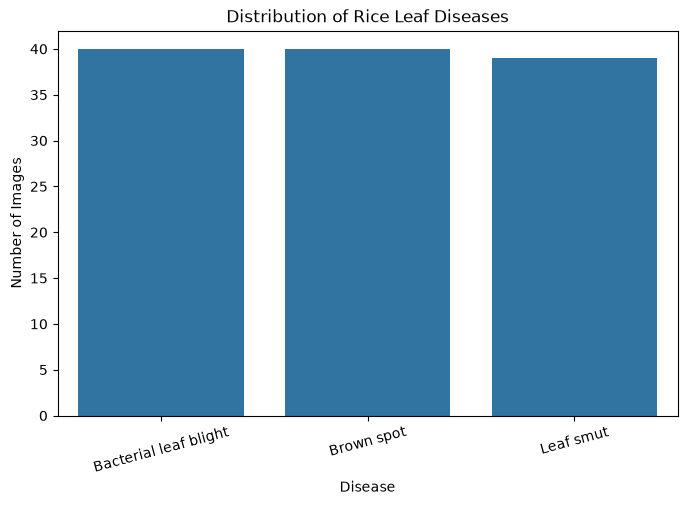

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="disease",
    order=df["disease"].value_counts().index
)

plt.title("Distribution of Rice Leaf Diseases")
plt.xlabel("Disease")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.show()

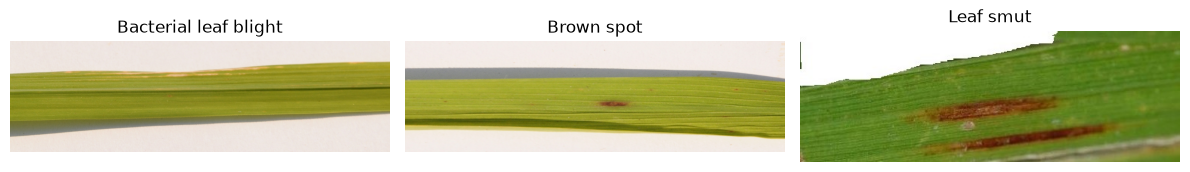

In [9]:
plt.figure(figsize=(12, 8))

classes = sorted(df["disease"].unique())

for i, disease in enumerate(classes):

    sample = df[df["disease"] == disease].sample(
        1, random_state=SEED
    ).iloc[0]

    img = Image.open(sample["image_path"])

    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(disease)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
dimensions = []

for path in df["image_path"]:

    img = Image.open(path)

    width, height = img.size

    dimensions.append({
        "width": width,
        "height": height,
        "format": img.format
    })

dimension_df = pd.DataFrame(dimensions)

print(dimension_df.describe())

print("\nImage formats:")
print(dimension_df["format"].value_counts())

             width      height
count   119.000000  119.000000
mean   2383.638655  707.739496
std    1123.528972  311.657582
min     250.000000   71.000000
25%    1074.000000  377.000000
50%    3081.000000  897.000000
75%    3081.000000  897.000000
max    3081.000000  900.000000

Image formats:
format
JPEG    119
Name: count, dtype: int64


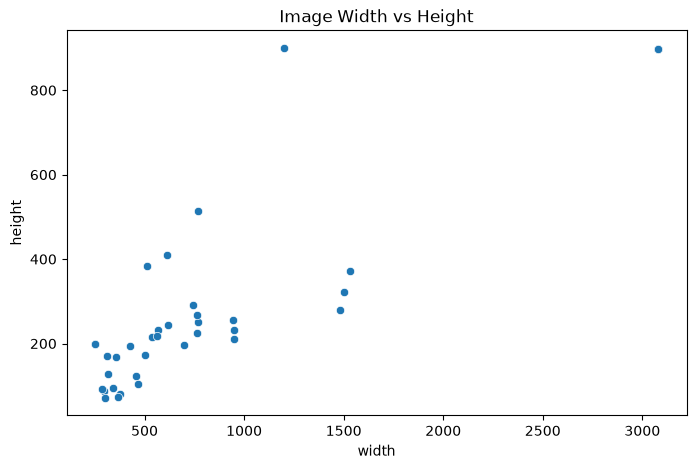

In [11]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=dimension_df,
    x="width",
    y="height"
)

plt.title("Image Width vs Height")
plt.show()

In [12]:
valid_images = []
corrupted_images = []

for path in df["image_path"]:

    try:
        img = Image.open(path)
        img.verify()

        valid_images.append(path)

    except Exception:
        corrupted_images.append(path)

print("Valid images:", len(valid_images))
print("Corrupted images:", len(corrupted_images))

Valid images: 119
Corrupted images: 0


In [13]:
IMG_SIZE = 224

X = []
y = []

class_names = sorted(df["disease"].unique())

class_to_index = {
    name: index
    for index, name in enumerate(class_names)
}

for _, row in df.iterrows():

    img = cv2.imread(row["image_path"])

    if img is None:
        continue

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    img = cv2.resize(
        img,
        (IMG_SIZE, IMG_SIZE)
    )

    X.append(img)

    y.append(class_to_index[row["disease"]])

X = np.array(X, dtype=np.float32) / 255.0
y = np.array(y)

print("Image data shape:", X.shape)
print("Labels shape:", y.shape)
print("Classes:", class_names)

Image data shape: (119, 224, 224, 3)
Labels shape: (119,)
Classes: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']


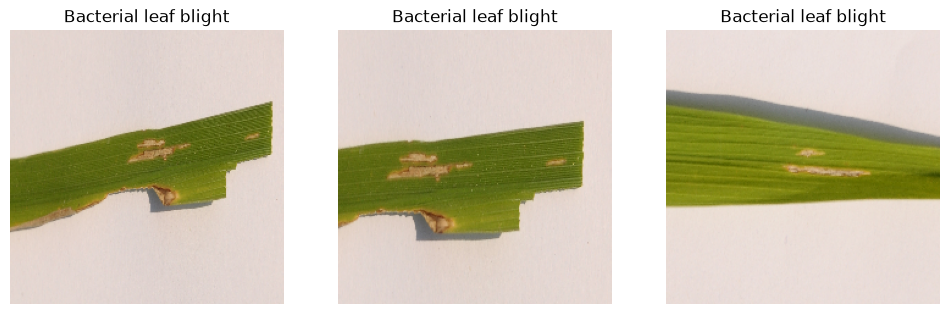

In [14]:
plt.figure(figsize=(12, 4))

for i in range(3):

    plt.subplot(1, 3, i + 1)

    plt.imshow(X[i])

    plt.title(class_names[y[i]])

    plt.axis("off")

plt.show()

In [15]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

Training images: 83
Validation images: 18
Testing images: 18


In [16]:
def extract_hog_features(images):

    hog_features = []

    for image in images:

        gray = cv2.cvtColor(
            (image * 255).astype(np.uint8),
            cv2.COLOR_RGB2GRAY
        )

        gray = cv2.resize(gray, (128, 128))

        hog = cv2.HOGDescriptor(
            (128, 128),
            (16, 16),
            (8, 8),
            (8, 8),
            9
        )

        features = hog.compute(gray)

        hog_features.append(features.flatten())

    return np.array(hog_features)


X_train_hog = extract_hog_features(X_train)
X_val_hog = extract_hog_features(X_val)
X_test_hog = extract_hog_features(X_test)

print(X_train_hog.shape)

(83, 8100)


In [17]:
svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1,
        gamma="scale",
        probability=True,
        random_state=SEED
    )
)

svm_model.fit(X_train_hog, y_train)

svm_predictions = svm_model.predict(X_test_hog)

print("SVM Accuracy:",
      accuracy_score(y_test, svm_predictions))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        svm_predictions,
        target_names=class_names,
        zero_division=0
    )
)

SVM Accuracy: 0.6666666666666666

Classification Report:
                       precision    recall  f1-score   support

Bacterial leaf blight       0.50      0.67      0.57         6
           Brown spot       0.50      0.33      0.40         6
            Leaf smut       1.00      1.00      1.00         6

             accuracy                           0.67        18
            macro avg       0.67      0.67      0.66        18
         weighted avg       0.67      0.67      0.66        18



In [18]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=SEED,
    max_depth=None
)

rf_model.fit(X_train_hog, y_train)

rf_predictions = rf_model.predict(X_test_hog)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=class_names,
        zero_division=0
    )
)

Random Forest Accuracy: 0.5555555555555556

Classification Report:
                       precision    recall  f1-score   support

Bacterial leaf blight       0.44      0.67      0.53         6
           Brown spot       0.33      0.17      0.22         6
            Leaf smut       0.83      0.83      0.83         6

             accuracy                           0.56        18
            macro avg       0.54      0.56      0.53        18
         weighted avg       0.54      0.56      0.53        18



In [19]:
cnn_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(
        32, (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        128, (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.5),

    layers.Dense(
        len(class_names),
        activation="softmax"
    )
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
history_cnn = cnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=8,
    verbose=1
)

Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 144ms/step - accuracy: 0.2892 - loss: 1.2225 - val_accuracy: 0.6111 - val_loss: 1.0607
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 124ms/step - accuracy: 0.5663 - loss: 0.9976 - val_accuracy: 0.6667 - val_loss: 0.7560
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 124ms/step - accuracy: 0.5422 - loss: 0.9444 - val_accuracy: 0.5556 - val_loss: 0.7499
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step - accuracy: 0.5783 - loss: 0.8643 - val_accuracy: 0.7778 - val_loss: 0.5853
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 124ms/step - accuracy: 0.7831 - loss: 0.5835 - val_accuracy: 0.7778 - val_loss: 0.4865
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 122ms/step - accuracy: 0.7952 - loss: 0.4834 - val_accuracy: 0.8333 - val_loss: 0.7474
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 125ms/step - accuracy: 0.8795 - loss: 0.3343 - val_accuracy: 0.6667 - val_loss: 1.1284
Epoch 8/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - accuracy: 0.8795 - loss: 0.3140 - val_accuracy: 0.

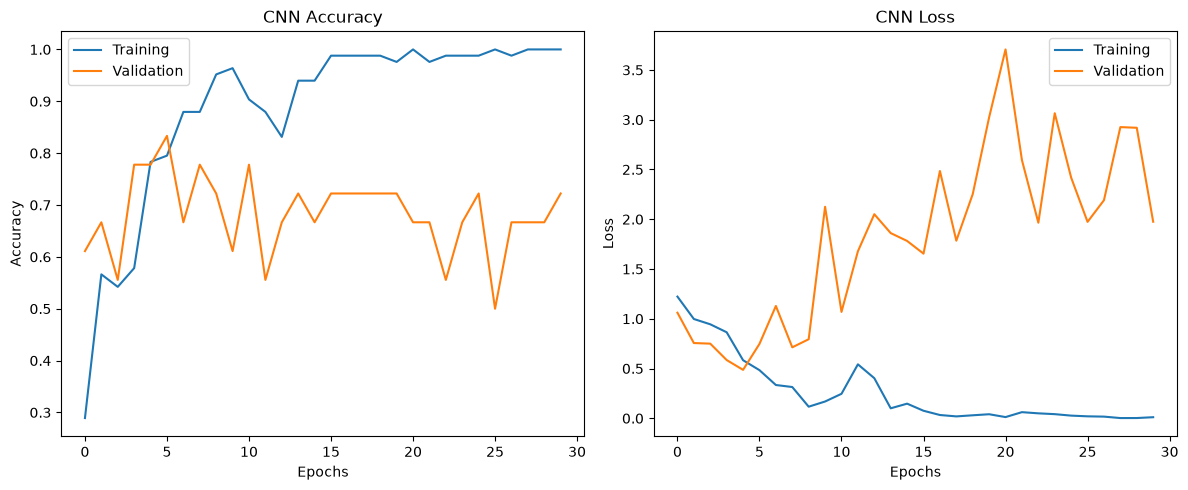

In [21]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history_cnn.history["accuracy"], label="Training")
plt.plot(history_cnn.history["val_accuracy"], label="Validation")

plt.title("CNN Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history_cnn.history["loss"], label="Training")
plt.plot(history_cnn.history["val_loss"], label="Validation")

plt.title("CNN Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [22]:
data_augmentation = models.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.15),

    layers.RandomZoom(0.15),

    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    ),

    layers.RandomContrast(0.1)

])

print("Data augmentation created!")

Data augmentation created!


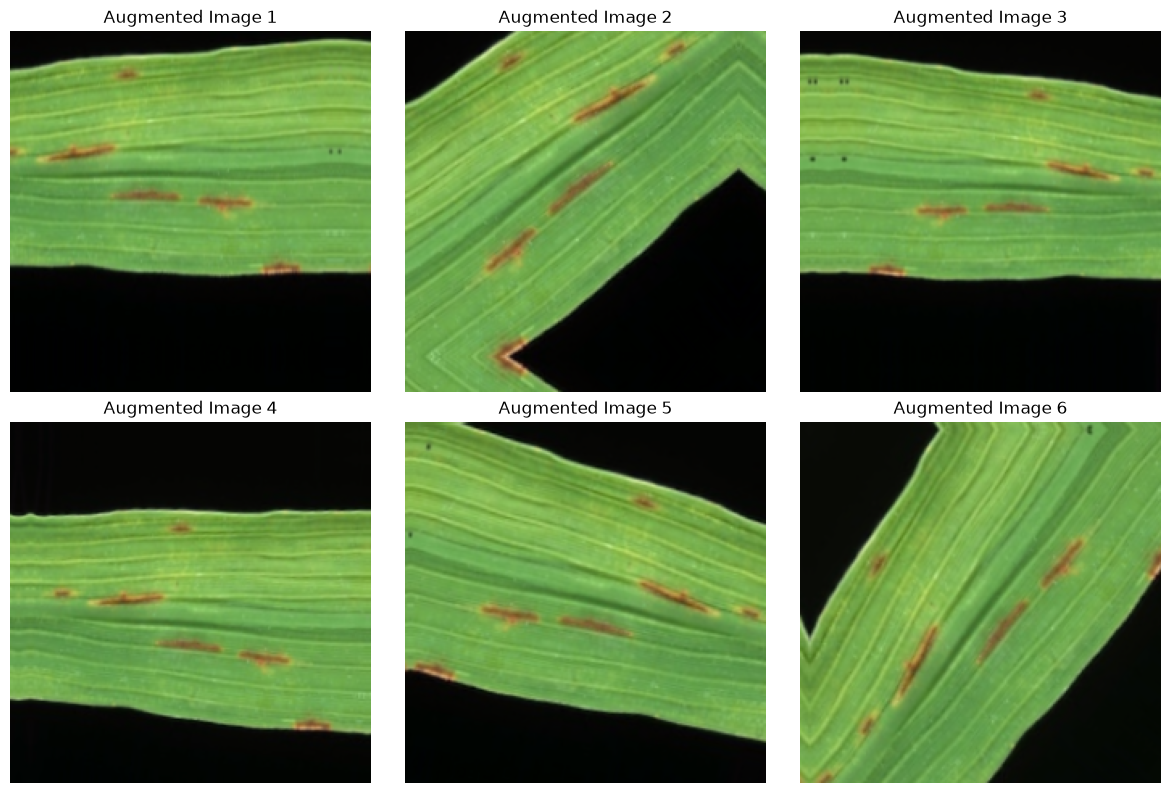

In [23]:
sample_image = X_train[0]

plt.figure(figsize=(12, 8))

for i in range(6):

    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, 0),
        training=True
    )[0].numpy()

    plt.subplot(2, 3, i + 1)

    plt.imshow(np.clip(augmented_image, 0, 1))

    plt.title(f"Augmented Image {i+1}")

    plt.axis("off")

plt.tight_layout()
plt.show()

In [24]:
aug_cnn_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Conv2D(
        32, (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        128, (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.5),

    layers.Dense(
        len(class_names),
        activation="softmax"
    )
])

aug_cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_aug = aug_cnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=8,
    verbose=1
)

Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 155ms/step - accuracy: 0.3494 - loss: 1.4386 - val_accuracy: 0.3333 - val_loss: 1.0959
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 135ms/step - accuracy: 0.2771 - loss: 1.1164 - val_accuracy: 0.4444 - val_loss: 1.0829
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 135ms/step - accuracy: 0.3133 - loss: 1.1040 - val_accuracy: 0.3333 - val_loss: 1.0726
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 134ms/step - accuracy: 0.3373 - loss: 1.0992 - val_accuracy: 0.3333 - val_loss: 1.0554
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 137ms/step - accuracy: 0.4337 - loss: 1.0925 - val_accuracy: 0.6667 - val_loss: 1.0474
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 136ms/step - accuracy: 0.4096 - loss: 1.0799 - val_accuracy: 0.6111 - val_loss: 0.9461
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 134ms/step - accuracy: 0.3735 - loss: 1.0705 - val_accuracy: 0.5000 - val_loss: 0.9546
Epoch 8/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 135ms/step - accuracy: 0.4337 - loss: 1.0485 - val_accuracy: 0.

In [25]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

transfer_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Rescaling(
        scale=2.0,
        offset=-1.0
    ),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.3),

    layers.Dense(
        len(class_names),
        activation="softmax"
    )
])

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

transfer_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)            │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [26]:
history_transfer = transfer_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=8,
    verbose=1
)


Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 252ms/step - accuracy: 0.3253 - loss: 1.3940 - val_accuracy: 0.4444 - val_loss: 0.8939
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step - accuracy: 0.4096 - loss: 1.3234 - val_accuracy: 0.6667 - val_loss: 0.7522
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.4940 - loss: 1.0820 - val_accuracy: 0.7778 - val_loss: 0.6442
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.5181 - loss: 1.0658 - val_accuracy: 0.8889 - val_loss: 0.5621
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.5783 - loss: 0.8773 - val_accuracy: 0.8889 - val_loss: 0.4994
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - accuracy: 0.6506 - loss: 0.8460 - val_accuracy: 0.8889 - val_loss: 0.4403
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - accuracy: 0.6265 - loss: 0.8290 - val_accuracy: 0.8889 - val_loss: 0.4034
Epoch 8/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step - accuracy: 0.7108 - loss: 0.7152 - val_accuracy: 0.

In [27]:


svm_pred = svm_model.predict(X_test_hog)

rf_pred = rf_model.predict(X_test_hog)




cnn_pred = np.argmax(
    cnn_model.predict(X_test, verbose=0),
    axis=1
)

aug_pred = np.argmax(
    aug_cnn_model.predict(X_test, verbose=0),
    axis=1
)

transfer_pred = np.argmax(
    transfer_model.predict(X_test, verbose=0),
    axis=1
)




predictions = {
    "HOG + SVM": svm_pred,
    "Random Forest": rf_pred,
    "CNN": cnn_pred,
    "CNN + Augmentation": aug_pred,
    "MobileNetV2": transfer_pred
}




results = []

for model_name, pred in predictions.items():

    results.append({

        "Model": model_name,

        "Accuracy": accuracy_score(y_test, pred),

        "Precision": precision_score(
            y_test, pred,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            y_test, pred,
            average="macro",
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test, pred,
            average="macro",
            zero_division=0
        )
    })


results_df = pd.DataFrame(results)

print(results_df.round(4))

                Model  Accuracy  Precision  Recall  F1 Score
0           HOG + SVM    0.6667     0.6667  0.6667    0.6571
1       Random Forest    0.5556     0.5370  0.5556    0.5296
2                 CNN    0.7222     0.7852  0.7222    0.7313
3  CNN + Augmentation    0.5556     0.5556  0.5556    0.5460
4         MobileNetV2    0.8889     0.9167  0.8889    0.8857


In [28]:
svm_pred = svm_model.predict(X_test_hog)
rf_pred = rf_model.predict(X_test_hog)

cnn_pred = np.argmax(
    cnn_model.predict(X_test, verbose=0),
    axis=1
)

aug_pred = np.argmax(
    aug_cnn_model.predict(X_test, verbose=0),
    axis=1
)

transfer_pred = np.argmax(
    transfer_model.predict(X_test, verbose=0),
    axis=1
)



predictions = {
    "HOG + SVM": svm_pred,
    "Random Forest": rf_pred,
    "CNN": cnn_pred,
    "CNN + Augmentation": aug_pred,
    "MobileNetV2": transfer_pred
}




results = []

for model_name, pred in predictions.items():

    results.append({

        "Model": model_name,

        "Accuracy": accuracy_score(y_test, pred),

        "Precision": precision_score(
            y_test, pred,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            y_test, pred,
            average="macro",
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test, pred,
            average="macro",
            zero_division=0
        )
    })


results_df = pd.DataFrame(results)

print(results_df.round(4))

                Model  Accuracy  Precision  Recall  F1 Score
0           HOG + SVM    0.6667     0.6667  0.6667    0.6571
1       Random Forest    0.5556     0.5370  0.5556    0.5296
2                 CNN    0.7222     0.7852  0.7222    0.7313
3  CNN + Augmentation    0.5556     0.5556  0.5556    0.5460
4         MobileNetV2    0.8889     0.9167  0.8889    0.8857


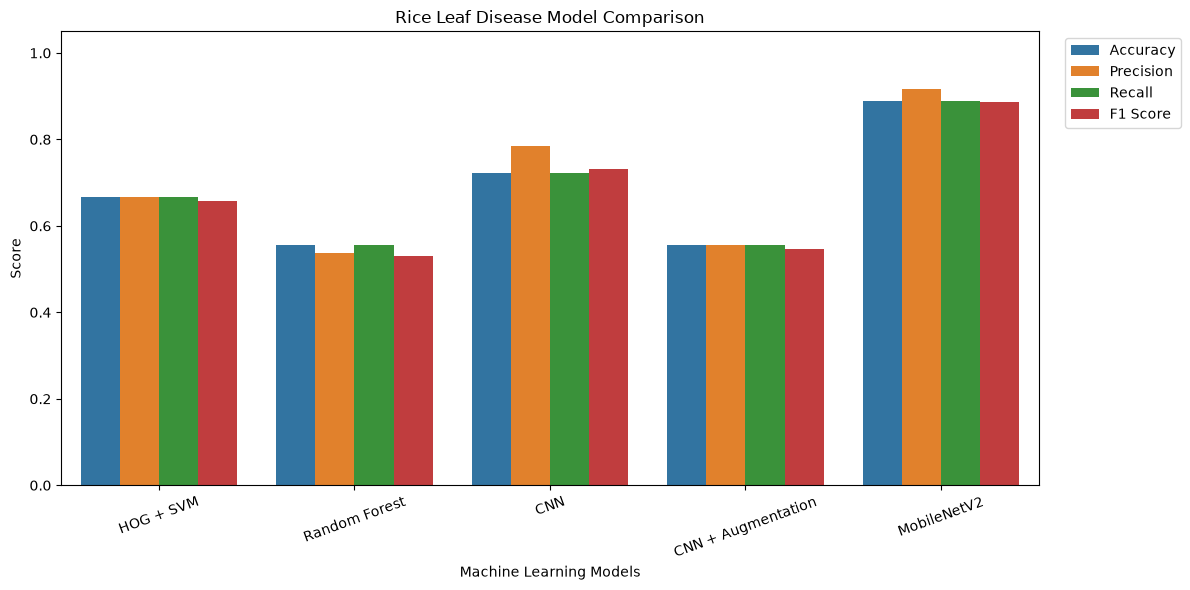

In [29]:
plt.figure(figsize=(12, 6))

results_melted = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Rice Leaf Disease Model Comparison")

plt.ylabel("Score")

plt.xlabel("Machine Learning Models")

plt.xticks(rotation=20)

plt.ylim(0, 1.05)

plt.legend(bbox_to_anchor=(1.02, 1))

plt.tight_layout()

plt.show()

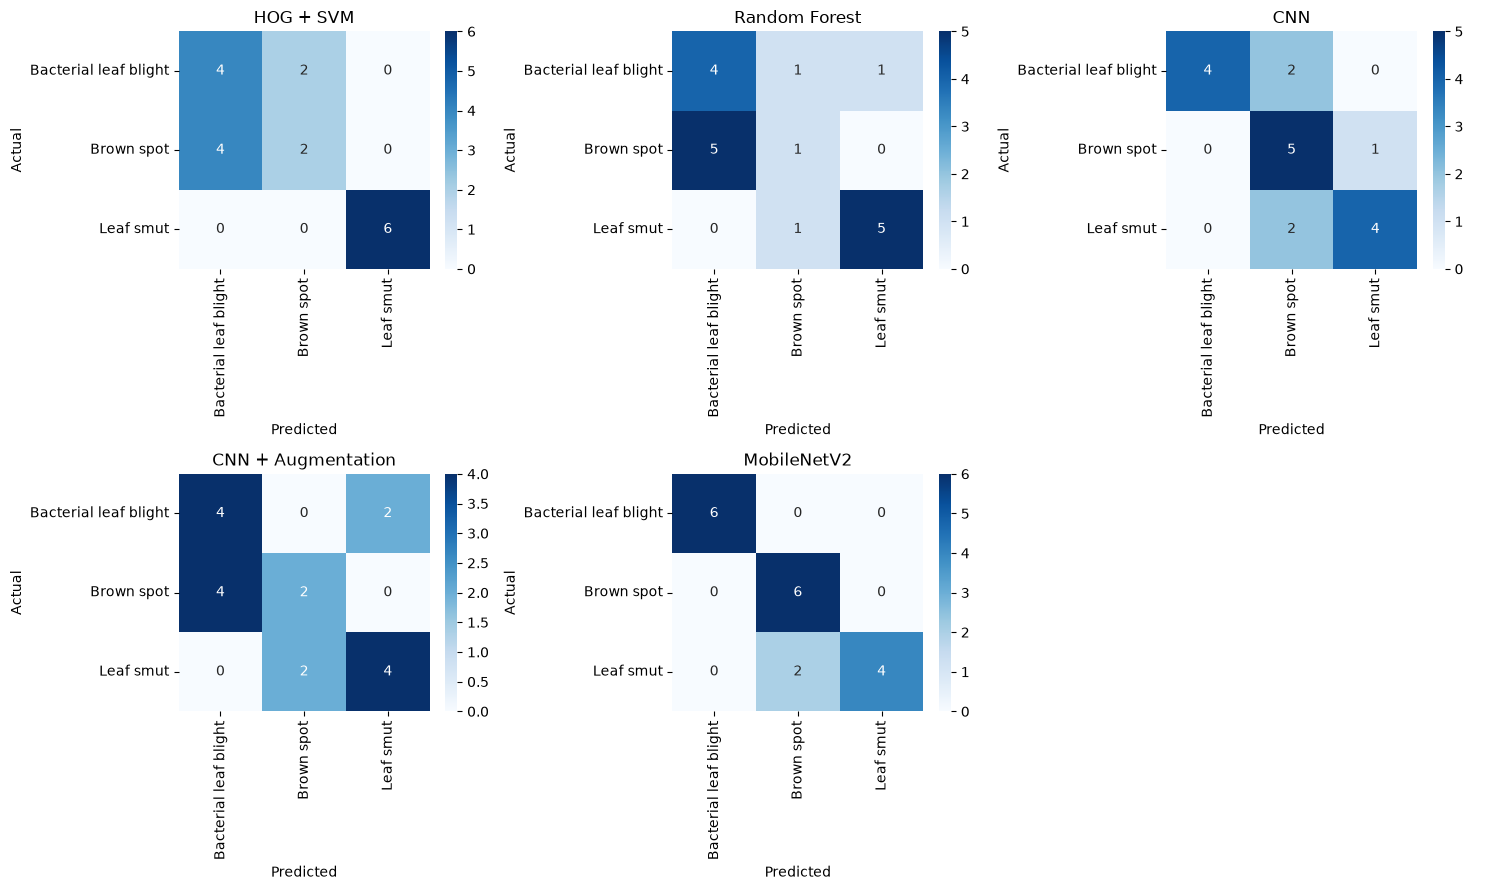

In [30]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9)
)

for ax, (model_name, pred) in zip(
    axes.flat,
    predictions.items()
):

    cm = confusion_matrix(
        y_test,
        pred,
        labels=np.arange(len(class_names))
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")


axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

In [31]:
for model_name, pred in predictions.items():

    print("\n", "=" * 50)

    print("MODEL:", model_name)

    print("=" * 50)

    print(
        classification_report(
            y_test,
            pred,
            labels=np.arange(len(class_names)),
            target_names=class_names,
            zero_division=0
        )
    )


MODEL: HOG + SVM
                       precision    recall  f1-score   support

Bacterial leaf blight       0.50      0.67      0.57         6
           Brown spot       0.50      0.33      0.40         6
            Leaf smut       1.00      1.00      1.00         6

             accuracy                           0.67        18
            macro avg       0.67      0.67      0.66        18
         weighted avg       0.67      0.67      0.66        18


MODEL: Random Forest
                       precision    recall  f1-score   support

Bacterial leaf blight       0.44      0.67      0.53         6
           Brown spot       0.33      0.17      0.22         6
            Leaf smut       0.83      0.83      0.83         6

             accuracy                           0.56        18
            macro avg       0.54      0.56      0.53        18
         weighted avg       0.54      0.56      0.53        18


MODEL: CNN
                       precision    recall  f1-score   suppo

In [32]:
best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(),
    "Model"
]

print("Best model based on macro F1-score:",
      best_model_name)

print("\nModel comparison:")
print(
    results_df.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)

Best model based on macro F1-score: MobileNetV2

Model comparison:
                Model  Accuracy  Precision  Recall  F1 Score
4         MobileNetV2    0.8889     0.9167  0.8889    0.8857
2                 CNN    0.7222     0.7852  0.7222    0.7313
0           HOG + SVM    0.6667     0.6667  0.6667    0.6571
3  CNN + Augmentation    0.5556     0.5556  0.5556    0.5460
1       Random Forest    0.5556     0.5370  0.5556    0.5296


In [33]:
def predict_rice_disease(image_path):

    img = Image.open(image_path).convert("RGB")

    img = img.resize((224, 224))

    img_array = np.array(img).astype("float32") / 255.0

    img_array = np.expand_dims(
        img_array,
        axis=0
    )

    prediction = transfer_model.predict(
        img_array,
        verbose=0
    )

    predicted_index = np.argmax(prediction[0])

    disease_name = class_names[predicted_index]

    confidence = prediction[0][predicted_index] * 100

    plt.figure(figsize=(5, 5))

    plt.imshow(img)

    plt.title(
        f"Prediction: {disease_name}\n"
        f"Confidence: {confidence:.2f}%"
    )

    plt.axis("off")

    plt.show()

    print("Predicted disease:", disease_name)

    print("Confidence:", round(float(confidence), 2), "%")

    return disease_name, confidence

In [34]:
import joblib

In [35]:
transfer_model.save("RiceLeaf_MobileNetV2.keras")

joblib.dump(svm_model, "RiceLeaf_SVM.pkl")

joblib.dump(rf_model, "RiceLeaf_RandomForest.pkl")

import json

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("Models saved successfully!")

Models saved successfully!


In [36]:
transfer_model.save("RiceLeaf_MobileNetV2.keras")

joblib.dump(
    svm_model,
    "RiceLeaf_SVM.pkl"
)

joblib.dump(
    rf_model,
    "RiceLeaf_RandomForest.pkl"
)

import json

with open("class_names.json", "w") as f:

    json.dump(class_names, f)

print("Models saved successfully!")

Models saved successfully!


In [37]:
results_df.sort_values(
    by="F1 Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
4,MobileNetV2,0.888889,0.916667,0.888889,0.885714
2,CNN,0.722222,0.785185,0.722222,0.731313
0,HOG + SVM,0.666667,0.666667,0.666667,0.657143
3,CNN + Augmentation,0.555556,0.555556,0.555556,0.546032
1,Random Forest,0.555556,0.537037,0.555556,0.529630



#  Model Comparison Report

## Introduction

In this project, five different machine learning and deep learning models were implemented to classify rice leaf diseases.

The models used were:

1. HOG + Support Vector Machine (SVM)
2. Random Forest
3. Convolutional Neural Network (CNN)
4. CNN with Data Augmentation
5. MobileNetV2 (Transfer Learning)

## Evaluation Metrics

The following evaluation metrics were used:

- Accuracy
- Precision
- Recall
- F1-score

Macro average metrics were used to give equal importance to all three disease classes.

## Model Performance

The performance of the five models was evaluated on the test dataset.

| Model | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| HOG + SVM | 66.67% | 66.67% | 66.67% | 65.71% |
| Random Forest | 55.56% | 53.70% | 55.56% | 52.96% |
| CNN | 72.22% | 78.52% | 72.22% | 73.13% |
| CNN + Augmentation | 55.56% | 55.56% | 55.56% | 54.60% |
| MobileNetV2 | 88.89% | 91.67% | 88.89% | 88.57% |

## Model Analysis

HOG + SVM achieved 66.67% accuracy by using image gradient and shape features.

Random Forest achieved 55.56% accuracy and showed comparatively lower classification performance.

CNN achieved 72.22% accuracy by automatically learning visual features from rice leaf images.

CNN with Data Augmentation achieved 55.56% accuracy. In this experiment, augmentation did not improve the model performance.

MobileNetV2 achieved the highest accuracy of 88.89% and the highest macro F1-score of 88.57%.

## Best Model Selection

Based on the experimental results, MobileNetV2 was selected as the best-performing model.

Its test accuracy was 88.89%.

Its macro precision was 91.67%.

Its macro recall was 88.89%.

Its macro F1-score was 88.57%.

MobileNetV2 performed better than the other tested models, possibly because transfer learning allowed it to reuse useful visual features learned from a large image dataset.




#  Challenges Faced and Solutions

## 1. Limited Dataset

**Challenge:**

The dataset contained only 119 images, with 40 images in each disease category. A small dataset can cause overfitting and reduce the model's ability to recognize new images.

**Solution:**

Data augmentation techniques such as flipping, rotation, zooming and translation were applied to increase the diversity of training images.

## 2. Different Image Dimensions

**Challenge:**

The images had different dimensions, which made it difficult to provide them directly to the deep learning models.

**Solution:**

All images were resized to 224 × 224 pixels to maintain a consistent input size.

## 3. Image Pixel Variations

**Challenge:**

Images contained pixel values ranging from 0 to 255.

**Solution:**

Pixel values were normalized to a range of 0 to 1 to make model training more consistent.

## 4. Overfitting

**Challenge:**

Because of the limited dataset, the model could memorize training images instead of learning general disease patterns.

**Solution:**

Dropout, data augmentation and validation data were used to reduce and monitor overfitting.

## 5. Similar Disease Symptoms

**Challenge:**

Different rice leaf diseases may have similar visual characteristics, such as spots, discoloration and damaged areas.

**Solution:**

CNN and transfer learning techniques were explored to identify important visual features and improve classification.

## 6. Limited Computational Resources

**Challenge:**

Training deep learning models can require considerable computational resources.

**Solution:**

MobileNetV2 was explored because it is a lightweight pretrained neural network suitable for transfer learning.

## 7. Model Selection

**Challenge:**

Different models produced different classification results, making it difficult to select the best model.

**Solution:**


##  Final Conclusion


The Rice Leaf Disease Detection project was developed to classify three types of rice leaf diseases: Leaf Smut, Brown Spot, and Bacterial Leaf Blight.

The dataset was analyzed using Exploratory Data Analysis techniques. Image preprocessing was performed through resizing, RGB conversion, and normalization.

Different machine learning and deep learning approaches were implemented, including HOG + SVM, Random Forest, CNN, CNN with Data Augmentation, and MobileNetV2.

Data augmentation techniques such as flipping, rotation, zooming, and translation were explored to improve model generalization.

All models were evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

Based on the experimental results, the best-performing model was identified as the preferred candidate for further development.

This project demonstrates how computer vision and deep learning can assist in identifying rice leaf diseases from images. Further improvements can be achieved by collecting more diverse images, testing under real agricultural conditions, and validating the model with independent datasets.